In [55]:
import os
import logging
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # 0 (default) = all messages, 1 = INFO messages, 2 = INFO and WARNING messages, 3 = only ERROR messages
logging.getLogger('tensorflow').setLevel(logging.ERROR)  # Suppress TensorFlow INFO and WARNING messages
import wfdb
import tensorflow as tf
from scipy.signal import butter, filtfilt, iirnotch
from matplotlib import pyplot as plt
import numpy as np
from utils.data_lists import *

In [2]:
def force_data(path, force_file):
    """
    Loads and preprocesses a force signal from a file.
    
    Arguments:
        - `path`: Path to the directory containing the force data file.
        - `force_file`: Filename of the force data file.
    
    Returns:
        A numpy array containing the filtered force signal.
    
    Raises:
        ValueError: If the finger name is not found in the filename.
        
    Details:
        - This function assumes the force data file follows a naming convention where the finger name is part of the filename.
        - It extracts the force signal for the specified finger from the file.
        - The first 5 samples are discarded, potentially corresponding to non-data values.
        - The signal is then filtered using a 4th order low-pass Butterworth filter with a specified cutoff frequency.
    
    Example usage:
    
    ```python
    force_signal = force_data(path, "finger2_data.txt")
    ```
    """
    finger_names = ["finger1", "finger2", "finger3", "finger4", "finger5"]
    # Sample rate and desired cutoff frequency (in Hz)
    fs = 100.0
    cutoff = 5.0
    for i, name in enumerate(finger_names):
        if name in force_file:
            force_signal = wfdb.rdsamp(os.path.join(path, force_file[:-4]))[0]
            force_signal = force_signal[5:]
            ######################################################
            # Filter the high frequencies
            ######################################################
            force_signal = butter_lowpass_filter(force_signal, cutoff, fs, order=4)
            return force_signal

def butter_lowpass(cutoff, fs, order=4):
    nyq = 0.5 * fs
    normal_cutoff = cutoff / nyq
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

def butter_lowpass_filter(data, cutoff, fs, order=4):
    b, a = butter_lowpass(cutoff, fs, order=order)
    y = filtfilt(b, a, data, axis=0)
    return y

In [3]:
path = 'data/1dof_dataset/'
emg_path = 'subject01_session1/1dof_preprocess_finger1_sample1.hea'
force_path = 'subject01_session1/1dof_force_finger1_sample1.hea'

In [4]:
emg_signal = wfdb.rdsamp(os.path.join(path, emg_path[:-4]))[0]
emg_signal = tf.cast(emg_signal, dtype=tf.float32)
force_signal = force_data(path, force_path)

In [5]:
print(f"Shape of emg signal: {emg_signal.shape}")
print(f"Shape of force signal: {force_signal.shape}")

Shape of emg signal: (51200, 256)
Shape of force signal: (2495, 5)


In [6]:
import numpy as np
from scipy import interpolate

def interpolate_force_to_emg(force_signal, emg_signal):
    """
    Interpola um sinal de força para ter o mesmo formato que um sinal de EMG.

    Parâmetros:
        - force_signal: array numpy com o sinal de força de entrada, com shape (n_samples_force, n_channels)
        - emg_signal: array numpy com o sinal de EMG de referência, com shape (n_samples_emg, n_channels)
    
    Retorna:
        - interpolated_signals: array numpy com os sinais de força interpolados, com shape (n_samples_emg, n_channels)
    
    Exemplo de uso:
        - interpolated_force = interpolate_force_to_emg(force_signal, emg_signal)
    """
    interpolated_signals = np.zeros((emg_signal.shape[0], force_signal.shape[1]))  # Array para armazenar os sinais interpolados

    for i in range(force_signal.shape[1]):  # Para cada canal de força
        x = np.arange(0, force_signal.shape[0])  # Índices originais do sinal de força
        y = force_signal[:, i]  # Valor do sinal de força
        f = interpolate.interp1d(x, y, kind='cubic')  # Função de interpolação cúbica
        x_new = np.linspace(0, force_signal.shape[0] - 1, emg_signal.shape[0])  # Novos índices para o sinal interpolado
        interpolated_signals[:, i] = f(x_new)  # Interpolar o sinal de força para o comprimento do sinal de EMG

    return interpolated_signals

In [7]:
interpolated_force = interpolate_force_to_emg(force_signal, emg_signal)

print(f"Shape of force signal: {interpolated_force.shape}")

Shape of force signal: (51200, 5)


In [8]:
def plot_signals(original_signal, interpolated_signal, signal_names):
    num_channels = original_signal.shape[1]
    fig, axs = plt.subplots(num_channels, 2, figsize=(14, 8))

    for i in range(num_channels):
        axs[i, 0].plot(original_signal[:, i], label='Original')
        axs[i, 0].set_title(f'Channel {i+1} - Original')
        axs[i, 1].plot(interpolated_signal[:, i], label='Interpolated', color='orange')
        axs[i, 1].set_title(f'Channel {i+1} - Interpolated')
        axs[i, 0].legend()
        axs[i, 1].legend()

    plt.tight_layout()
    plt.show()

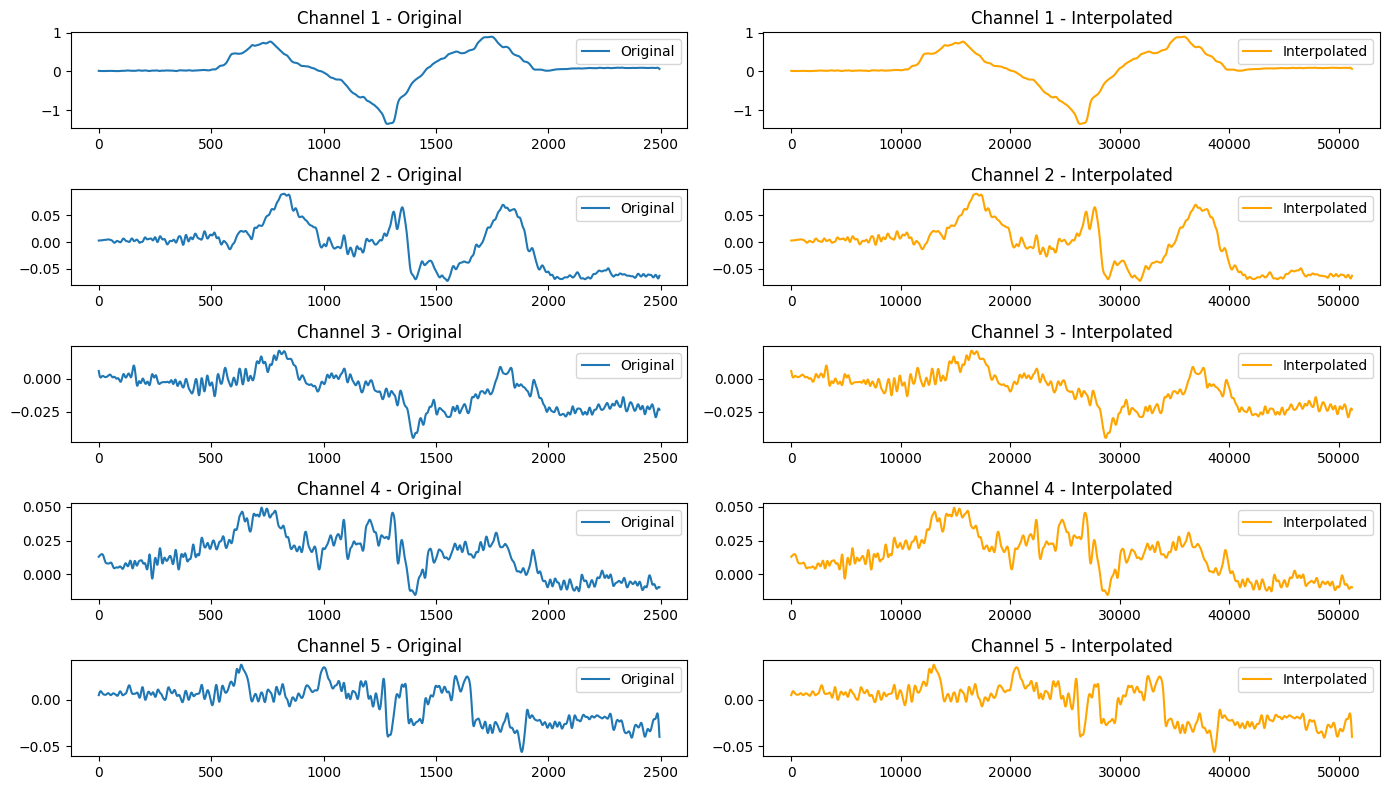

In [9]:
plot_signals(force_signal/0.3, interpolated_force/0.3, signal_names=["Force Channel 1", "Force Channel 2", "Force Channel 3", "Force Channel 4", "Force Channel 5"])

In [120]:
def force_data(path, force_file):
    """
    Loads and preprocesses a force signal from a file.
    
    Arguments:
        - `path`: Path to the directory containing the force data file.
        - `force_file`: Filename of the force data file.
    
    Returns:
        A numpy array containing the filtered force signal.
    
    Raises:
        ValueError: If the finger name is not found in the filename.
        
    Details:
        - This function assumes the force data file follows a naming convention where the finger name is part of the filename.
        - It extracts the force signal for the specified finger from the file.
        - The first 5 samples are discarded, potentially corresponding to non-data values.
        - The signal is then filtered using a 4th order low-pass Butterworth filter with a specified cutoff frequency.
    
    Example usage:
    
    ```python
    force_signal = force_data(path, "finger2_data.txt")
    ```
    """
    finger_names = ["finger1", "finger2", "finger3", "finger4", "finger5"]
    # Sample rate and desired cutoff frequency (in Hz)
    fs = 100.0
    cutoff = 5.0
    for i, name in enumerate(finger_names):
        if name in force_file:
            force_signal = wfdb.rdsamp(os.path.join(path, force_file[:-4]))[0]
            force_signal = force_signal[5:]
            # Filter the high frequencies
            force_signal = butter_lowpass_filter(force_signal, cutoff, fs, order=4)
            # Normalize by dividing by the maximum absolute value
            max_abs_value = np.max(np.abs(force_signal))
            force_signal /= max_abs_value
            return force_signal

def interpolate_force_to_emg(force_signal, emg_signal):
    """
    Interpolates a force signal to have the same shape as an EMG signal.

    Parameters:
        - force_signal: numpy array with the input force signal, with shape (n_samples_force, n_channels)
        - emg_signal: numpy array with the reference EMG signal, with shape (n_samples_emg, n_channels)
    
    Returns:
        - interpolated_signals: numpy array with the interpolated force signals, with shape (n_samples_emg, n_channels)
    
    Example usage:
        - interpolated_force = interpolate_force_to_emg(force_signal, emg_signal)
    """
    interpolated_signals = np.zeros((emg_signal.shape[0], force_signal.shape[1]))  # Array to store interpolated signals

    for i in range(force_signal.shape[1]):  # For each force channel
        x = np.arange(0, force_signal.shape[0])  # Original indices of the force signal
        y = force_signal[:, i]  # Value of the force signal
        f = interpolate.interp1d(x, y, kind='cubic')  # Cubic interpolation function
        x_new = np.linspace(0, force_signal.shape[0] - 1, emg_signal.shape[0])  # New indices for the interpolated signal
        interpolated_signals[:, i] = f(x_new)  # Interpolate the force signal to the length of the EMG signal

    return interpolated_signals

def synced_windows(emg_signal, force_signal, window_size=100, shift=1):
    """
    Create windows from EMG and force signals using tf.slice.

    Arguments:
        emg_signal: EMG signal tensor.
        force_signal: Force signal tensor.
        emg_window_size: Size of the EMG window (default: 100).
        force_window_size: Size of the force window (default: 1).
    
    Returns:
        A TensorFlow dataset containing synchronized EMG and force windows.
    """
    # Adjust the signal
    emg_windows = tf.data.Dataset.from_tensor_slices(emg_signal[:-window_size-shift+1])
    force_windows = tf.data.Dataset.from_tensor_slices(force_signal[window_size+shift-1:-1])
    
    # Extract EMG windows
    emg_windows = emg_windows.window(window_size, shift=shift, drop_remainder=True)
    force_windows = force_windows.window(1, shift=shift)

    # Convert to windows of desired size
    emg_windows = emg_windows.flat_map(lambda x: x.batch(window_size))
    force_windows = force_windows.flat_map(lambda x: x.batch(1))

    # Create the dataset
    dataset = tf.data.Dataset.zip((emg_windows, force_windows))
    return dataset

def create_synced_datasets(path, emg_files, force_files, window_size=100, stride=1):
    """
    Creates a TensorFlow dataset by loading, processing, and combining synchronized EMG and force signals from multiple files.
    
    Arguments:
        - `path`: Path to the directory containing the data files.
        - `emg_files`: List of filenames for the EMG files.
        - `force_files`: List of filenames for the force files.
        - `window_size`: Size of the window in samples to split the signals (default: 100).
        - `stride`: Step size of the window in samples when splitting the signals (default: 1).
    
    Returns:
        A TensorFlow dataset containing synchronized windows of EMG and force signals from all the files.
    """
    datasets = []

    # if not isinstance(emg_files, list):
    #     emg_files = [emg_files]
    # if not isinstance(force_files, list):
    #     force_files = [force_files]

    # path = str(path)[2:-1]
    # emg_files = [str(byte_string)[2:-1] for byte_string in emg_files]
    # force_files = [str(byte_string)[2:-1] for byte_string in force_files]

    for emg_file, force_file in zip(emg_files, force_files):
        # Load EMG and force signals
        emg_signal = wfdb.rdsamp(os.path.join(path, emg_file[:-4]))[0]
        emg_signal = tf.cast(emg_signal, dtype=tf.float32)

        force_signal = force_data(path, force_file)
        force_signal = interpolate_force_to_emg(force_signal, emg_signal)

        # Create the dataset for the finguers
        finger_dataset = synced_windows(emg_signal, force_signal)
        # Apply preprocessing to force signals
        finger_dataset = finger_dataset.map(lambda x, y: (x, preprocess_force(y)))

        datasets.append(finger_dataset)

    dataset = datasets[0]
    for i in range(1, len(datasets)):
        dataset = dataset.concatenate(datasets[i])
    return dataset

def create_synced_datasets_generator(paths, emg_files_list, force_files_list, window_size=100):
    """
    Yields datasets generated from processing multiple data files in a generator fashion.

    Arguments:
        - `paths`: A list of paths to the directories containing the data files.
        - `emg_files_list`: A list of lists containing filenames for the EMG files for each path.
        - `force_files_list`: A list of lists containing filenames for the force files for each path.
        - `window_size`: Size of the window in samples to split the signals (default: 100).

    Yields:
        A TensorFlow dataset containing synchronized windows of EMG and force signals from a single file pair.
    """
    for path in paths:
        for emg_file, force_file in zip(emg_files_list, force_files_list):
            yield from create_synced_datasets(path, emg_file, force_file, window_size=window_size)

def preprocess_force(force):
    # Reshape label to match the expected shape
    force = tf.squeeze(force, axis=0)
    return force

def generate_dataset(paths, emg_paths, force_paths):
    return create_synced_datasets_generator(paths, emg_paths, force_paths)

In [121]:
subject_number = 2

subjects = []
base_path = 'data/1dof_dataset/'

# Create the path for the dataset, based on subject number
subject_path1 = f"subject{subject_number:02d}_session1/"
subject_path2 = f"subject{subject_number:02d}_session2/"

# Path of the first session
session1_path = os.path.join(base_path, subject_path1)

# Path of the second session
session2_path = os.path.join(base_path, subject_path2)

subjects.append([session1_path, session2_path])

# Create a path for the dataset
path1 = [subjects[0][0]]
path2 = [subjects[0][1]]
path3 = [subjects[0][1]]

In [122]:
dataset = tf.data.Dataset.from_generator(
    create_synced_datasets_generator,
    args=(path1, [emg_tr_files_lists], [force_tr_files_lists]),
    output_types=(tf.float32, tf.float32),  # Define output types (EMG, force)
    output_shapes=(tf.TensorShape([100, 256]),
                  tf.TensorShape([5,]))
)

In [123]:
dataset = (
    tf.data.Dataset.from_generator(
        lambda: create_synced_datasets_generator(
            path1, emg_tr_files_lists, force_tr_files_lists
        ),
        output_signature=(
            tf.TensorSpec(
                shape=(100, 256), dtype=tf.float32
            ),
            tf.TensorSpec(shape=(5,), dtype=tf.float32),
        ),
    )
)

In [124]:
for emg_window, force_target in dataset.take(1):
    print("EMG Window:")
    print(emg_window.shape)
    print("Force Target:")
    print(force_target.shape)
    print()

EMG Window:
(100, 256)
Force Target:
(5,)



In [125]:
dataset

<_FlatMapDataset element_spec=(TensorSpec(shape=(100, 256), dtype=tf.float32, name=None), TensorSpec(shape=(5,), dtype=tf.float32, name=None))>

In [126]:
force_signal = []
for emg, f in dataset:
    force_signal.append(tf.expand_dims(f, axis=1))
# Converter a lista de previsões em um tensor
force_signal = tf.concat(force_signal, axis=1)

OutOfRangeError: {{function_node __wrapped__ExpandDims_device_/job:localhost/replica:0/task:0/device:GPU:0}} End of sequence [Op:ExpandDims] name: 

In [127]:
print(len(force_signal))

305942


In [128]:
np.array(force_signal).shape

(305942, 5, 1)

In [129]:
force_signal = np.array(force_signal)[:, :, 0]

np.array(force_signal).shape

(305942, 5)

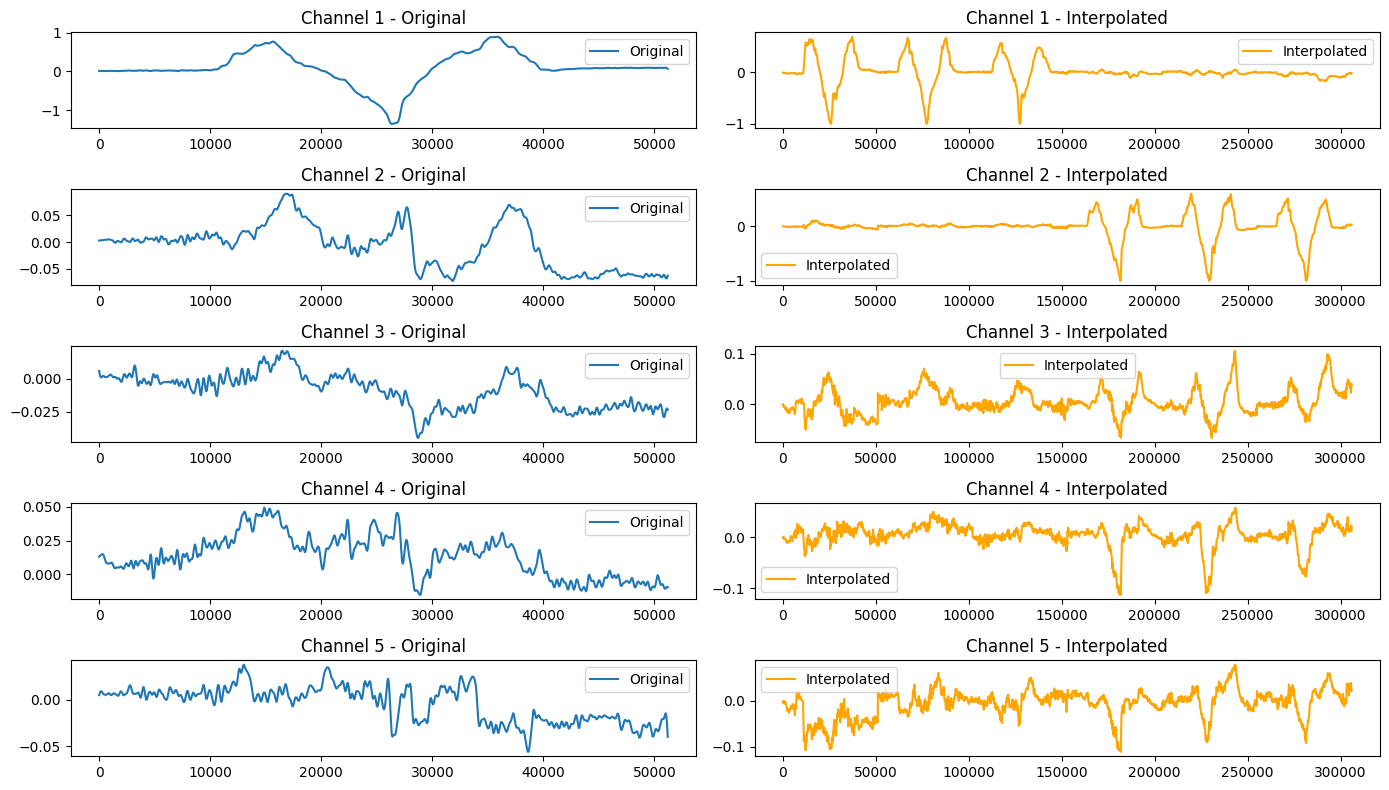

In [130]:
plot_signals(interpolated_force/0.3, force_signal, signal_names=["Force Channel 1", "Force Channel 2", "Force Channel 3", "Force Channel 4", "Force Channel 5"])

In [1]:
import tensorflow as tf

2024-03-05 11:43:27.038615: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2024-03-05 11:43:27.431768: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-03-05 11:43:27.431829: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-03-05 11:43:27.502723: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-03-05 11:43:27.647990: I tensorflow/core/platform/cpu_feature_guar

In [32]:
input_matrix = tf.constant([[1, 2, 3, 4, 5, 6, 7, 8],
                            [9, 10, 11, 12, 13, 14, 15, 16],
                            [17, 18, 19, 20, 21, 22, 23, 24],
                            [25, 26, 27, 28, 29, 30, 31, 32],
                            [33, 34, 35, 36, 37, 38, 39, 40],
                            [41, 42, 43, 44, 45, 46, 47, 48],
                            [49, 50, 51, 52, 53, 54, 55, 56],
                            [57, 58, 59, 60, 61, 62, 63, 64]], dtype=tf.float32)

# Calculate the differential matrix
differential_matrix = input_matrix[1:, :] - input_matrix[:-1, :]

# Print the result
print(differential_matrix)

tf.Tensor(
[[8. 8. 8. 8. 8. 8. 8. 8.]
 [8. 8. 8. 8. 8. 8. 8. 8.]
 [8. 8. 8. 8. 8. 8. 8. 8.]
 [8. 8. 8. 8. 8. 8. 8. 8.]
 [8. 8. 8. 8. 8. 8. 8. 8.]
 [8. 8. 8. 8. 8. 8. 8. 8.]
 [8. 8. 8. 8. 8. 8. 8. 8.]], shape=(7, 8), dtype=float32)


In [60]:
def calculate_differential_matrices(input_array, num_chunks):
    """
    Calculates differential matrices for each sample in a 1D TensorFlow tensor.
    Args:
        input_array: A 2D TensorFlow tensor with shape [num_samples, 256].
        num_chunks: The number of chunks to divide each sample into.
    Returns:
        A 3D TensorFlow tensor with shape [num_samples, num_chunks, 7].
        Contains differential matrices for each sample and chunk.
    Raises:
        ValueError: If the sample length (256) is not divisible by num_chunks * 8.
    """
    
    # Check if sample length is divisible by required amount
    if 256 % (num_chunks * 8) != 0:
        raise ValueError("Sample length must be divisible by num_chunks * 8")
    # Iterate over each sample in the input tensor
    differential_matrices = []
    for sample in input_array:
        # Split the sample into chunks of appropriate size
        chunk_length = len(sample) // num_chunks
        chunks = tf.split(sample, num_or_size_splits=len(sample) // chunk_length)
        # Reshape each chunk into a matrix of size 8x8
        matrices = [tf.reshape(chunk, (8, 8)) for chunk in chunks]
        # Apply the differential matrix operation to each matrix
        sample_diff_matrices = []
        for matrix in matrices:
            differential_matrix = matrix[1:, :] - matrix[:-1, :]
            sample_diff_matrices.append(differential_matrix)
        # Concatenate the differential matrices for this sample
        sample_result = tf.concat(sample_diff_matrices, axis=0)
        # Add the sample's differential matrices to the result list
        differential_matrices.append(sample_result)
    
    # Combine differential matrices for all samples into a single tensor
    result = tf.stack(differential_matrices, axis=0)
    # Reshape the combined tensor into a 2D array
    return tf.reshape(result, (tf.shape(result)[0], -1))

In [61]:
def electrode_selection(emg_signal):
    indices = tf.concat([tf.range(64, 128), tf.range(192, 256)], axis=0)
    emg_signal = tf.gather(emg_signal, indices, axis=1)
    emg_signal = tf.cast(emg_signal, dtype=tf.float32)
    return emg_signal

In [62]:
def electrode_selection(emg_signal):
    """
    Selects a subset of electrodes from an EMG signal.
    Args:
        emg_signal: A 2D TensorFlow tensor representing the EMG signal, with
        shape (num_electrodes, time_steps).
    Returns:
        A 2D TensorFlow tensor representing the selected EMG signal, with shape
        (64, time_steps), containing channels from electrodes 64 to 127 and
        192 to 255 (inclusive).
    Raises:
        ValueError: If the input `emg_signal` does not have a rank of 2.
    """
    
    # Check if input has the expected rank
    if len(emg_signal.shape) != 2:
        raise ValueError("Input emg_signal must have a rank of 2.")
    # Create a tensor of indices for the desired electrodes
    indices = tf.concat([tf.range(64, 128), tf.range(192, 256)], axis=0)
    # Select the desired electrodes using tf.gather
    emg_signal = tf.gather(emg_signal, indices, axis=1)
    # Cast the selected signal to float32 for consistency
    emg_signal = tf.cast(emg_signal, dtype=tf.float32)
    return emg_signal

In [63]:
input_array = tf.random.normal(shape=[100, 256])
num_chunks = 2

result = calculate_differential_matrices(
    electrode_selection(input_array),
    num_chunks
)

# Print the result
print(result.shape)

(100, 112)


In [64]:
input_array

<tf.Tensor: shape=(100, 256), dtype=float32, numpy=
array([[ 1.2911127 ,  1.5659982 ,  0.30213833, ..., -2.2684703 ,
        -0.4953019 ,  0.8571787 ],
       [ 2.2220778 ,  0.6723029 , -0.99795634, ...,  0.27441794,
         0.08556487, -1.3784332 ],
       [ 0.7010149 , -1.2413114 , -0.10773604, ..., -0.09302647,
         0.4094087 ,  0.20522031],
       ...,
       [-0.83109236,  0.47608593, -0.698422  , ..., -0.08163989,
        -0.12511785,  0.2359103 ],
       [ 2.621927  ,  0.22439222, -0.00392487, ..., -2.3770838 ,
        -1.9108038 , -1.1094621 ],
       [ 0.39337695,  1.6219953 ,  1.0987722 , ...,  0.9482386 ,
         0.73926604,  0.09205852]], dtype=float32)>

In [65]:
result

<tf.Tensor: shape=(100, 112), dtype=float32, numpy=
array([[-0.84711134,  2.0716658 , -2.8408508 , ..., -3.6534045 ,
        -0.8401198 ,  0.3577102 ],
       [ 1.0725095 , -0.2653465 , -0.19882151, ...,  0.7869549 ,
         0.62799704, -0.79472977],
       [-2.0967455 , -1.5082867 ,  1.3683028 , ...,  1.8774983 ,
        -1.0116013 ,  0.1340341 ],
       ...,
       [-1.5610921 ,  0.57556295, -0.2777701 , ...,  0.91394657,
         0.07759012, -0.32420892],
       [ 1.5498319 ,  1.6043532 ,  0.88133097, ..., -3.6969597 ,
        -1.6982143 , -1.1826265 ],
       [ 1.3774152 ,  0.65706825, -0.5234103 , ...,  0.6073513 ,
         0.39300832,  0.8851    ]], dtype=float32)>